# ARTI 402 — Deep Learning
## Lab 11 — Generative Models: VAEs and GANs

**Week 11 · Variational Autoencoders and Generative Adversarial Networks**
Making the latent space mean something, and then inventing data that never existed.

| | |
|---|---|
| **Prerequisites** | Lab 9 (autoencoders) above all.|
| **Reference** | Kingma & Welling (2013) · Goodfellow et al. (2014) |


### Read and reference

| When | Resource |
|---|---|
| **Before class** | [Arxiv Insights — *Variational Autoencoders*](https://www.youtube.com/watch?v=9zKuYvjFFS8) |
| **Stage 2** | [Lilian Weng — *From Autoencoder to Beta-VAE*](https://lilianweng.github.io/posts/2018-08-12-vae/)|
| **Stage 5** | [Google — GAN Lab](https://poloclub.github.io/ganlab/)|
| **Reference** | [Goodfellow's NIPS 2016 tutorial](https://arxiv.org/abs/1701.00160)|
### How to work through the notebook
* Sections are labelled **Idea** (read and run), **Exercise** (you write code) and **Checkpoint** (a short answer).
* Every exercise cell is marked `# TODO`. Do not delete the cells above it — later cells depend on them.
* Run cells **in order**, top to bottom. If something breaks, restart the kernel and run all.
* The graded **Assessment** is at the very end.

---
## Setup

The visualization helpers are defined in this notebook; no separate helper file is needed.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

np.set_printoptions(precision=3, suppress=True)

digits = load_digits()
X = digits.data / 16.0
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y)

print("train:", X_train.shape, " test:", X_test.shape)
print("the same 8 x 8 digits as Lab 9")

train: (1347, 64)  test: (450, 64)
the same 8 x 8 digits as Lab 9


In [2]:
def draw_vae_architecture(d_in=64, hidden=32, latent=8):
    """Draw the VAE encoder, distribution parameters, sample, and decoder."""
    labels = [
        ("Input", f"{d_in} pixels"),
        ("Encoder", f"{hidden} hidden units"),
        ("Mean", f"mu: {latent} values"),
        ("Log variance", f"logvar: {latent} values"),
        ("Sample", "z = mu + sigma * eps"),
        ("Decoder", f"{hidden} hidden units"),
        ("Output", f"{d_in} pixels"),
    ]
    colors = ["#DCEAF7", "#CDE8D2", "#F8D98B", "#F8D98B",
              "#E9D5F5", "#CDE8D2", "#DCEAF7"]
    fig, ax = plt.subplots(figsize=(13, 3.2))
    xs = np.linspace(0.06, 0.94, len(labels))
    for i, ((title, detail), x) in enumerate(zip(labels, xs)):
        ax.text(x, 0.55, f"{title}\n{detail}", ha="center", va="center",
                fontsize=8, bbox=dict(boxstyle="round,pad=0.45",
                                      fc=colors[i], ec="#52616B"))
        if i < len(labels) - 1:
            ax.annotate("", xy=(xs[i + 1] - 0.055, 0.55),
                        xytext=(x + 0.055, 0.55),
                        arrowprops=dict(arrowstyle="->", color="#52616B"))
    ax.set_xlim(0, 1)
    ax.set_ylim(0.15, 0.95)
    ax.axis("off")
    ax.set_title("Variational autoencoder")
    fig.tight_layout()
    return fig, ax


def draw_reparameterization():
    """Illustrate moving randomness outside the differentiable expression."""
    fig, ax = plt.subplots(figsize=(8, 3.2))
    nodes = [
        (0.16, "mu", "encoder mean", "#DCEAF7"),
        (0.43, "logvar", "encoder log variance", "#DCEAF7"),
        (0.70, "eps", "random N(0, 1)", "#F8D98B"),
        (0.88, "z", "mu + exp(0.5 logvar) * eps", "#CDE8D2"),
    ]
    for x, name, detail, color in nodes:
        ax.text(x, 0.55, f"{name}\n{detail}", ha="center", va="center",
                fontsize=9, bbox=dict(boxstyle="round,pad=0.55",
                                      fc=color, ec="#52616B"))
    ax.annotate("", xy=(0.82, 0.58), xytext=(0.23, 0.58),
                arrowprops=dict(arrowstyle="->", color="#52616B"))
    ax.annotate("", xy=(0.82, 0.52), xytext=(0.50, 0.52),
                arrowprops=dict(arrowstyle="->", color="#52616B"))
    ax.annotate("", xy=(0.82, 0.46), xytext=(0.76, 0.46),
                arrowprops=dict(arrowstyle="->", color="#52616B"))
    ax.text(0.50, 0.16, "Gradients flow through mu and logvar; eps is fixed input noise.",
            ha="center", fontsize=9)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    ax.set_title("The reparameterization trick")
    fig.tight_layout()
    return fig, ax


def draw_gan_setup():
    """Diagram the generator-discriminator contest."""
    fig, ax = plt.subplots(figsize=(9, 3.2))
    nodes = [
        (0.12, "Noise z", "#F8D98B"),
        (0.38, "Generator G", "#CDE8D2"),
        (0.62, "Fake sample", "#E9D5F5"),
        (0.84, "Discriminator D", "#DCEAF7"),
    ]
    for x, label, color in nodes:
        ax.text(x, 0.60, label, ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.6", fc=color, ec="#52616B"))
    for x0, x1 in [(0.18, 0.31), (0.45, 0.55), (0.69, 0.76)]:
        ax.annotate("", xy=(x1, 0.60), xytext=(x0, 0.60),
                    arrowprops=dict(arrowstyle="->", color="#52616B", lw=1.5))
    ax.text(0.62, 0.20, "Real samples also enter D", ha="center", fontsize=9)
    ax.annotate("", xy=(0.82, 0.48), xytext=(0.62, 0.29),
                arrowprops=dict(arrowstyle="->", color="#4C78A8"))
    ax.text(0.50, 0.90, "G tries to fool D; D learns to distinguish real from fake",
            ha="center", fontsize=10)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.axis("off")
    fig.tight_layout()
    return fig, ax


def draw_gan_progress(steps, g_mean, g_std, p_real, p_fake,
                      target_mean=3.0, target_std=0.5):
    """Plot generator distribution and discriminator confidence during training."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
    left.plot(steps, g_mean, marker="o", label="Generated mean")
    left.axhline(target_mean, color="#777777", linestyle="--", label="Target mean")
    left.plot(steps, g_std, marker="s", label="Generated standard deviation")
    left.axhline(target_std, color="#E45756", linestyle=":", label="Target std")
    left.set_xlabel("Training step")
    left.set_title("Generator distribution")
    left.grid(alpha=0.25)
    left.legend(fontsize=8)

    right.plot(steps, p_real, marker="o", label="D(real)")
    right.plot(steps, p_fake, marker="s", label="D(fake)")
    right.axhline(0.5, color="#777777", linestyle="--", label="Chance")
    right.set_ylim(0, 1)
    right.set_xlabel("Training step")
    right.set_title("Discriminator confidence")
    right.grid(alpha=0.25)
    right.legend()
    fig.tight_layout()
    return fig, (left, right)


def draw_digit_grid(panels, n=10, titles=None, suptitle=None):
    """Display rows of flattened 8x8 grayscale digit images."""
    n = min(n, len(panels[0][1]))
    fig, axes = plt.subplots(len(panels), n, figsize=(1.35 * n, 1.7 * len(panels)),
                             squeeze=False)
    for row, (row_label, images) in enumerate(panels):
        images = np.asarray(images).reshape(len(images), 8, 8)
        for col in range(n):
            ax = axes[row, col]
            ax.imshow(images[col], cmap="gray_r", vmin=0, vmax=1,
                      interpolation="nearest")
            ax.axis("off")
            if row == 0 and titles is not None:
                ax.set_title(str(titles[col]), fontsize=8)
            if col == 0:
                ax.set_ylabel(row_label, rotation=0, ha="right",
                              va="center", labelpad=40, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle)
        fig.tight_layout(rect=(0, 0, 1, 0.92))
    else:
        fig.tight_layout()
    return fig, axes


def draw_latent_space(Z, labels):
    """Display a two-dimensional latent representation by class."""
    Z = np.asarray(Z)
    fig, ax = plt.subplots(figsize=(6, 5))
    points = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10",
                        vmin=0, vmax=9, s=20, alpha=0.75)
    fig.colorbar(points, ax=ax, ticks=np.arange(10), label="Digit")
    ax.set_xlabel("Latent dimension 1")
    ax.set_ylabel("Latent dimension 2")
    ax.set_title("Latent space")
    ax.grid(alpha=0.2)
    fig.tight_layout()
    return fig, ax


print("figure helpers loaded")

figure helpers loaded


---
# Stage 1 · The gap left at the end of Lab 9

## Idea 1 — Invent a code and see what comes out

Lab 9 finished with a challenge. Your autoencoder's decoder turns a code into an image. So could
you *invent* a code — pick a few numbers out of the air, decode them, and get a digit nobody ever
drew?

Let us actually try it. Everything below runs a plain autoencoder, exactly Lab 9's, and then asks
its decoder to make something up.

First the machinery. Read this cell, run it, and move on — you will write the parts that matter in
Stage 2.

In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -30, 30)))


class VAE:
    """64 -> 32 -> (mu, logvar) of size L -> 32 -> 64.

    With beta = 0 in the loss this behaves as Lab 9's plain autoencoder.
    With beta = 1 it is a variational autoencoder.
    """

    def __init__(self, L=8, H=32, seed=0):
        r = np.random.RandomState(seed)
        he = lambda a, b: r.randn(a, b) * np.sqrt(2.0 / a)
        self.W1,  self.b1  = he(64, H), np.zeros(H)
        self.Wmu, self.bmu = he(H, L),  np.zeros(L)     # the centre of the code
        self.Wlv, self.blv = he(H, L),  np.zeros(L)     # its log variance
        self.W3,  self.b3  = he(L, H),  np.zeros(H)
        self.W4,  self.b4  = he(H, 64), np.zeros(64)
        self.L = L

    def encode(self, X):
        h = np.maximum(0, X @ self.W1 + self.b1)
        return h, h @ self.Wmu + self.bmu, h @ self.Wlv + self.blv

    def decode(self, z):
        h2 = np.maximum(0, z @ self.W3 + self.b3)
        return h2, sigmoid(h2 @ self.W4 + self.b4)


print("VAE class ready - note the encoder returns TWO things, not one")

VAE class ready - note the encoder returns TWO things, not one


That is the first real difference from Lab 9, and it is worth stopping on.

Lab 9's encoder returned **one vector**: the code. This encoder returns **two** — a centre `mu` and
a spread `logvar`. It no longer says "this image is at point *z*". It says "this image lives
*somewhere around here*, and here is how uncertain I am."

Why that matters becomes obvious the moment you try to generate.

---
# Stage 2 · Two new ideas

## Idea 2 — Make the code a distribution

Here is the whole architecture. Compare it with Lab 9's hourglass — the two ends are identical and
the middle has changed completely.

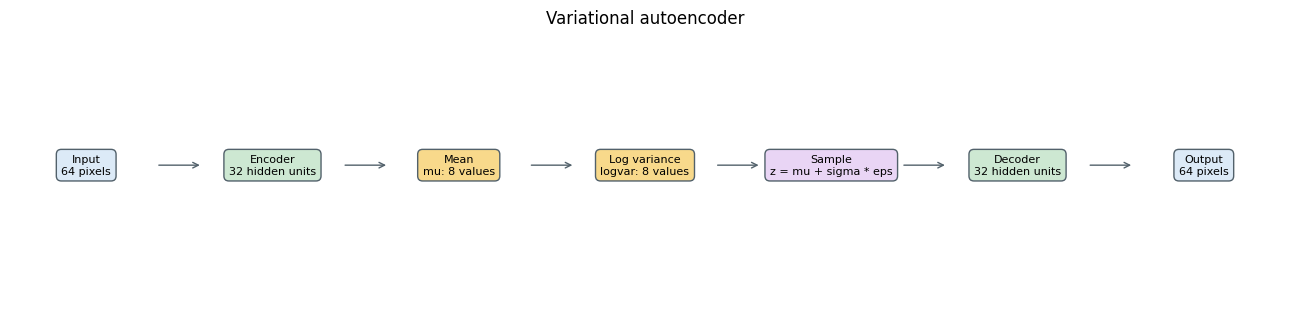

In [4]:
draw_vae_architecture(d_in=64, hidden=32, latent=8)
plt.show()

Two forces now act on the middle, and they pull against each other:

* the **reconstruction loss** wants codes spread far apart, so every image gets its own private
  corner and rebuilds perfectly;
* the **KL term** wants every code to look like a draw from a standard normal $N(0, 1)$ —
  centred, unit width, no empty gaps.

The second force is the entire point. If the codes genuinely look like draws from $N(0, 1)$, then
**a draw from $N(0, 1)$ looks like a code** — and the decoder will know what to do with it. That is
what Lab 9 was missing.

## Idea 3 — The reparameterization trick

There is a problem, and it is not obvious until you try to train this.

To get a code we must **sample** from the distribution the encoder described. But sampling is a
random operation, and you cannot differentiate through randomness — there is no derivative of
"draw a random number" with respect to `mu`. Backpropagation hits the sampling step and stops.

The trick is to move the randomness out of the way: instead of sampling *inside* the network,
draw $\varepsilon \sim N(0,1)$ **outside** it and feed it in as an input.

$$z = \mu + \sigma \odot \varepsilon \qquad \text{where} \qquad \sigma = \exp(\tfrac{1}{2}\log\sigma^2)$$

Now `z` is an ordinary arithmetic expression in `mu` and `logvar`. The randomness is still there,
but it arrives as data rather than as an operation, and gradients flow straight through.

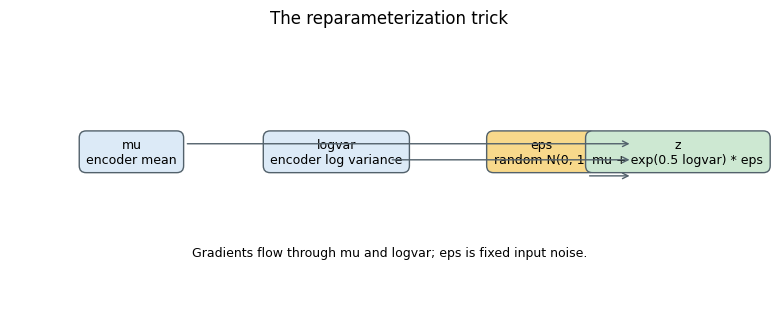

In [5]:
draw_reparameterization()
plt.show()

> **Why `logvar` and not `sigma`?** Because a standard deviation must be positive, and nothing stops
> a linear layer outputting a negative number. Predicting the **logarithm** of the variance lets the
> network output anything at all, and `exp(0.5 * logvar)` is positive whatever it says. The same
> reasoning you met in Lab 2, where logits were unconstrained and softmax did the squashing.

### Exercise 1 — the trick, in one line

In [6]:
def reparameterize(mu, logvar, rng):
    """Draw z = mu + sigma * eps, with eps from a standard normal.

    Returns (eps, z) - eps is kept because the backward pass needs it.
    """
    # Completed 1: draw eps, the same shape as mu, from a standard normal
    #         (use rng.randn(*mu.shape))
    eps = rng.randn(*mu.shape)

    # Completed 2: sigma from logvar - exp of half the log variance
    sigma = np.exp(0.5 * logvar)

    # Completed 3: z = mu + sigma * eps
    z = mu + sigma * eps

    return eps, z


# --- self-check -------------------------------------------------
rng = np.random.RandomState(0)
mu_t = np.array([[0.0, 5.0]])
lv_t = np.array([[np.log(1.0), np.log(0.0001)]])   # second dim almost certain
samples = np.array([reparameterize(mu_t, lv_t, rng)[1][0] for _ in range(2000)])

print(f"dim 0 (variance 1.0000): mean {samples[:,0].mean():6.3f}  std {samples[:,0].std():.3f}")
print(f"dim 1 (variance 0.0001): mean {samples[:,1].mean():6.3f}  std {samples[:,1].std():.3f}")

assert abs(samples[:, 0].std() - 1.0) < 0.1, "dim 0 should have std about 1"
assert samples[:, 1].std() < 0.05, "dim 1 said it was certain - it should barely move"
assert abs(samples[:, 1].mean() - 5.0) < 0.05, "dim 1 should sit at its mu"
print("\nA confident dimension barely moves. An uncertain one wanders.")

dim 0 (variance 1.0000): mean -0.044  std 0.983
dim 1 (variance 0.0001): mean  5.000  std 0.010

A confident dimension barely moves. An uncertain one wanders.


### Exercise 2 — the KL term

The KL divergence measures how far one distribution is from another. For a Gaussian with mean
$\mu$ and variance $\sigma^2$ against a standard normal, it has a closed form — no integration
needed:

$$D_{KL} = -\tfrac{1}{2}\sum_j \left(1 + \log\sigma_j^2 - \mu_j^2 - \sigma_j^2\right)$$

Read what it rewards. The sum is zero exactly when every $\mu_j = 0$ and every $\sigma_j^2 = 1$.
Drift away from the origin and $\mu_j^2$ punishes you. Get too confident, shrinking $\sigma$ towards
zero, and $-\log\sigma_j^2$ blows up. It is a spring pulling the codes back to a tidy ball at the
origin.

In [7]:
def kl_divergence(mu, logvar):
    """Mean KL divergence per sample, against a standard normal."""
    n = len(mu)
    # Completed: the formula above, summed over everything, divided by n
    #       (np.exp(logvar) is sigma squared)
    return -0.5 * np.sum(1 + logvar - mu**2 - np.exp(logvar)) / n


# --- self-check -------------------------------------------------
perfect = kl_divergence(np.zeros((4, 3)), np.zeros((4, 3)))
shifted = kl_divergence(np.full((4, 3), 2.0), np.zeros((4, 3)))
narrow  = kl_divergence(np.zeros((4, 3)), np.full((4, 3), np.log(0.01)))

print(f"mu=0, var=1   (already standard normal) : {perfect:.3f}")
print(f"mu=2, var=1   (drifted off centre)      : {shifted:.3f}")
print(f"mu=0, var=0.01 (too confident)          : {narrow:.3f}")

assert abs(perfect) < 1e-9, "a standard normal should score exactly 0"
assert shifted > 5, "drifting off centre must be punished"
assert narrow > 5, "collapsing the variance must be punished too"

mu=0, var=1   (already standard normal) : -0.000
mu=2, var=1   (drifted off centre)      : 6.000
mu=0, var=0.01 (too confident)          : 5.423


Zero for a perfect match, and a penalty in both directions. That is the shape of every well-behaved
regularizer you have met — Lab 6's L2 did the same job for weights.

### Exercise 3 — the full loss

The VAE's loss is the two forces added together, with a dial between them:

$$\mathcal{L} = \underbrace{\text{BCE}(\hat{x}, x)}_{\text{rebuild it}} \; + \; \beta \cdot \underbrace{D_{KL}}_{\text{keep it tidy}}$$

$\beta = 1$ is the VAE from the paper. $\beta = 0$ removes the KL entirely and leaves you with
Lab 9's plain autoencoder — which is exactly how we will run the comparison.

In [8]:
def vae_loss(X, x_hat, mu, logvar, beta=1.0):
    """Returns (reconstruction, kl, total). Reconstruction is binary cross-entropy."""
    n = len(X)
    eps = 1e-9
    recon = -np.sum(X * np.log(x_hat + eps) + (1 - X) * np.log(1 - x_hat + eps)) / n

    # Completed 1: the KL term, using the function you wrote
    kl = kl_divergence(mu, logvar)

    # Completed 2: the total - reconstruction plus beta times KL
    total = recon + beta * kl

    return recon, kl, total


# --- self-check ---
m_ = VAE(L=8, seed=0)
h_, mu_, lv_ = m_.encode(X_train[:16])
_, z_ = reparameterize(mu_, lv_, np.random.RandomState(0))
_, xh_ = m_.decode(z_)
r_, k_, t_ = vae_loss(X_train[:16], xh_, mu_, lv_, beta=1.0)
print(f"untrained:  reconstruction {r_:.2f}   KL {k_:.3f}   total {t_:.2f}")
assert abs(t_ - (r_ + k_)) < 1e-9, "with beta=1 the total is just the sum"
r0, k0, t0 = vae_loss(X_train[:16], xh_, mu_, lv_, beta=0.0)
assert abs(t0 - r0) < 1e-9, "with beta=0 the KL should not contribute"
print("with beta = 0 the loss is reconstruction only - a plain autoencoder")

untrained:  reconstruction 56.95   KL 1.941   total 58.89
with beta = 0 the loss is reconstruction only - a plain autoencoder


### Checkpoint 1

1. The encoder outputs `mu` and `logvar` instead of one code vector. What does the pair say that a
   single vector cannot?
2. Explain in two sentences why sampling inside the network breaks backpropagation, and how moving
   `eps` to the input fixes it.
3. The KL term punishes both drifting away from the origin *and* becoming too certain. Why would
   punishing only the first not be enough?

#### Answers

1. mu is the center of the code distribution, while logvar describes its uncertainty in each latent dimension. A single vector gives a point but not how much variation is plausible around that point.
2. A random sample inside the network is not a differentiable operation, so the gradient cannot pass through it to the encoder. Instead, draw eps independently and compute z = mu + exp(0.5 * logvar) * eps; this arithmetic expression has gradients with respect to mu and logvar.
3. Penalizing only the mean would let the encoder set mu to zero while shrinking its variance toward zero, collapsing every input to nearly the same code. The variance part of the KL penalty discourages that collapse and keeps the code distribution near the standard normal.


---
# Stage 3 · Training it

## Idea 4 — The backward pass, provided and checked

You wrote full backprop by hand in Lab 5, so there is nothing new in principle here — just more
chain rule, including one new path where the gradient splits and travels through both `mu` and
`logvar`.

The cell below provides it, along with an Adam optimizer. **Run it and move on**, but do look at
`dmu` and `dlv`: each is a sum of two terms, one from the reconstruction and one from the KL. That
is the two forces, written as code.

In [9]:
PARAMS = ['W1', 'b1', 'Wmu', 'bmu', 'Wlv', 'blv', 'W3', 'b3', 'W4', 'b4']


def backward(m, X, h, mu, lv, eps, z, h2, x_hat, beta):
    n = len(X)
    g = {}
    da4 = (x_hat - X) / n                       # sigmoid + BCE, fused as in Lab 2
    g['W4'] = h2.T @ da4;  g['b4'] = da4.sum(0)
    dh2 = da4 @ m.W4.T;    dh2[h2 <= 0] = 0
    g['W3'] = z.T @ dh2;   g['b3'] = dh2.sum(0)
    dz = dh2 @ m.W3.T

    dmu = dz + beta * mu / n                                        # recon + KL
    dlv = dz * eps * 0.5 * np.exp(0.5 * lv) + beta * 0.5 * (np.exp(lv) - 1) / n

    g['Wmu'] = h.T @ dmu;  g['bmu'] = dmu.sum(0)
    g['Wlv'] = h.T @ dlv;  g['blv'] = dlv.sum(0)
    dh = dmu @ m.Wmu.T + dlv @ m.Wlv.T;  dh[h <= 0] = 0
    g['W1'] = X.T @ dh;    g['b1'] = dh.sum(0)
    return g


def train_vae(L=8, H=32, beta=1.0, epochs=400, batch_size=64, lr=2e-3,
              seed=0, data=None):
    Xd = X_train if data is None else data
    m = VAE(L, H, seed=seed)
    rng = np.random.RandomState(seed)
    adam = {k: [np.zeros_like(getattr(m, k)), np.zeros_like(getattr(m, k))]
            for k in PARAMS}
    t = 0
    for ep in range(epochs):
        perm = rng.permutation(len(Xd))
        for s in range(0, len(Xd), batch_size):
            Xb = Xd[perm[s:s + batch_size]]
            h, mu, lv = m.encode(Xb)
            eps, z = reparameterize(mu, lv, rng)
            h2, xh = m.decode(z)
            g = backward(m, Xb, h, mu, lv, eps, z, h2, xh, beta)
            t += 1
            for k, G in g.items():
                mt, vt = adam[k]
                mt[:] = 0.9 * mt + 0.1 * G
                vt[:] = 0.999 * vt + 0.001 * G * G
                P = getattr(m, k)
                P -= lr * (mt / (1 - 0.9 ** t)) / (np.sqrt(vt / (1 - 0.999 ** t)) + 1e-8)
    return m


def evaluate(m, Xd, beta=1.0, seed=7):
    h, mu, lv = m.encode(Xd)
    eps, z = reparameterize(mu, lv, np.random.RandomState(seed))
    h2, xh = m.decode(z)
    r, k, tot = vae_loss(Xd, xh, mu, lv, beta)
    return r, k, mu


print("training machinery ready")

training machinery ready


### Exercise 4 — check the gradients, as always

Lab 5's rule stands: never trust a hand-written backward pass you have not checked. Compare it
against a numerical gradient, holding `eps` fixed so the loss is deterministic.

In [10]:
m_chk = VAE(L=3, H=16, seed=1)
Xb = X_train[:6]
h, mu, lv = m_chk.encode(Xb)
eps_fixed, z = reparameterize(mu, lv, np.random.RandomState(0))
h2, xh = m_chk.decode(z)
g = backward(m_chk, Xb, h, mu, lv, eps_fixed, z, h2, xh, beta=1.0)


def loss_with_fixed_eps(m, X, eps):
    h, mu, lv = m.encode(X)
    z = mu + np.exp(0.5 * lv) * eps              # same eps every time
    h2, xh = m.decode(z)
    r, k, total = vae_loss(X, xh, mu, lv, beta=1.0)
    return total


worst = 0.0
step = 1e-5
for name in PARAMS:
    P = getattr(m_chk, name)
    for trial in range(6):
        ix = tuple(np.random.RandomState(trial).randint(0, s) for s in P.shape)
        original = P[ix]
        # Completed: central difference - nudge up, nudge down, put it back
        P[ix] = original + step;  L_plus  = loss_with_fixed_eps(m_chk, Xb, eps_fixed)
        P[ix] = original - step;  L_minus = loss_with_fixed_eps(m_chk, Xb, eps_fixed)
        P[ix] = original
        numeric = (L_plus - L_minus) / (2 * step)
        worst = max(worst, abs(numeric - g[name][ix]) / max(abs(numeric), 1e-8))

print(f"worst relative error across all 10 parameter arrays: {worst:.2e}")
assert worst < 1e-4, "the backward pass and the definition of a derivative disagree"
print("the gradients are correct")

worst relative error across all 10 parameter arrays: 1.98e-06
the gradients are correct


### Exercise 5 — train it, and then invent a digit

This is the experiment the whole lab is built around. Train two models on identical data with
identical code, differing **only** in `beta`:

* `beta = 0` — no KL term. This is Lab 9's plain autoencoder.
* `beta = 1` — the VAE.

Then ask both to generate, by drawing codes from $N(0,1)$ and decoding them.

In [11]:
t0 = time.time()
ae  = train_vae(L=8, beta=0.0, epochs=400)      # plain autoencoder
vae = train_vae(L=8, beta=1.0, epochs=400)      # variational autoencoder
print(f"both trained in {time.time() - t0:.1f}s")

for name, m, b in [("plain AE (beta=0)", ae, 0.0), ("VAE (beta=1)", vae, 1.0)]:
    r, k, mu = evaluate(m, X_test, beta=b)
    print(f"{name:20}  reconstruction {r:6.2f}   KL {k:6.2f}   "
          f"code std {mu.std():.2f}")

print("\nThe KL term asked for code std = 1. Look at which model delivered it.")

both trained in 12.4s
plain AE (beta=0)     reconstruction  17.24   KL  86.33   code std 2.46
VAE (beta=1)          reconstruction  20.90   KL   3.49   code std 0.67

The KL term asked for code std = 1. Look at which model delivered it.


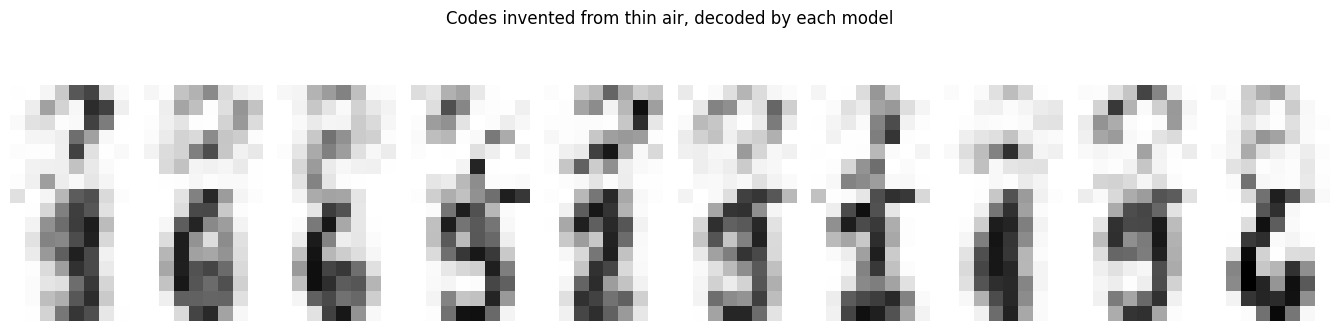

In [12]:
rng_gen = np.random.RandomState(42)

# Completed 1: draw 10 codes from a STANDARD NORMAL, shape (10, 8)
z_invented = rng_gen.randn(10, 8)

# Completed 2: decode them with each model (decode returns two things; keep the second)
_, made_by_ae  = ae.decode(z_invented)
_, made_by_vae = vae.decode(z_invented)

draw_digit_grid([("plain AE", made_by_ae), ("VAE", made_by_vae)],
                suptitle="Codes invented from thin air, decoded by each model")
plt.show()

assert z_invented.shape == (10, 8), "ten codes, eight numbers each"

Look at the two rows. The plain autoencoder produces smudges, as Lab 9 predicted. The VAE produces
things that look like digits.

Nothing about the decoder is different between the two. The only change is that one of them was
trained with a term insisting its codes look like draws from $N(0,1)$ — so when you hand it a draw
from $N(0,1)$, it recognises the neighbourhood.

### Exercise 6 — measure it, do not just look

Eyeballing is not evidence. Train a classifier on *real* digits and use it as a judge: show it the
generated images and see how confident it is. A confident judge means the image looks like a
digit; a hesitant one means it does not.

In [13]:
judge = LogisticRegression(max_iter=3000).fit(X_train, y_train)
print(f"judge's accuracy on real digits: {judge.score(X_test, y_test):.3f}")
print(f"judge's confidence on real digits: "
      f"{judge.predict_proba(X_test).max(axis=1).mean():.3f}\n")


def generation_score(m, latent=8, n=300, seed=42):
    """Mean confidence of the judge on n images invented by this model."""
    zs = np.random.RandomState(seed).randn(n, latent)
    # Completed: decode zs, then return the judge's mean max probability
    _, generated = m.decode(zs)
    return judge.predict_proba(generated).max(axis=1).mean()


print(f"plain AE (beta=0) : {generation_score(ae):.3f}")
print(f"VAE      (beta=1) : {generation_score(vae):.3f}")

assert generation_score(vae) > generation_score(ae), \
    "the VAE should generate more convincingly"

judge's accuracy on real digits: 0.969
judge's confidence on real digits: 0.903

plain AE (beta=0) : 0.495
VAE      (beta=1) : 0.676


---
# Stage 4 · Turning the dial too far

## Idea 5 — Posterior collapse

If $\beta = 1$ beats $\beta = 0$ at generating, more pressure should be better still. Try
$\beta = 4$ and watch something instructive go wrong.

In [14]:
print(f"{'beta':>6}{'recon':>9}{'KL':>8}{'code std':>11}{'judge confidence':>19}")
results = {}
for beta in [0.0, 1.0, 4.0]:
    m = train_vae(L=8, beta=beta, epochs=400)
    r, k, mu = evaluate(m, X_test, beta=beta)
    conf = generation_score(m)
    results[beta] = (r, k, mu.std(), conf)
    print(f"{beta:6.1f}{r:9.2f}{k:8.2f}{mu.std():11.2f}{conf:19.3f}")

print(f"\nreal digits, for reference:"
      f"{judge.predict_proba(X_test).max(axis=1).mean():>36.3f}")

  beta    recon      KL   code std   judge confidence
   0.0    17.24   86.33       2.46              0.495
   1.0    20.90    3.49       0.67              0.676
   4.0    27.21    0.00       0.01              0.300

real digits, for reference:                               0.903


Read the $\beta = 4$ row carefully. The KL is **0.00** and the code standard deviation is
essentially **zero**. The encoder has given up: it now outputs the same code — the origin — for
every image, because that is what the KL term is screaming for and the KL term is shouting four
times louder than the reconstruction loss.

The decoder, receiving no information at all, learns to produce a single blurry average digit.

This is called **posterior collapse**, and it is the characteristic failure of VAEs. It is not an
exotic edge case; practitioners fight it constantly, usually by warming $\beta$ up slowly from
zero during training.

> **The pattern, for the fourth time.** Lab 6: too much L2 and the weights die. Lab 9: too tight a
> bottleneck and reconstruction fails. Lab 10: no $\sqrt{d_k}$ and the softmax saturates. Here: too
> much KL and the encoder stops speaking. Every regularizer has a setting at which it destroys the
> thing it was meant to improve.

### Exercise 7 — walking through the latent space

One more property worth seeing. Take two real digits, encode both, and walk in a straight line
from one code to the other, decoding at each step. If the space is as tidy as the KL term was
trying to make it, every point along the way should decode to something plausible.

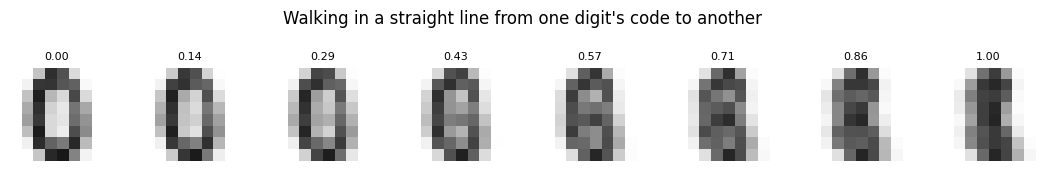

the judge reads this sequence as: [np.int64(0), np.int64(0), np.int64(0), np.int64(8), np.int64(8), np.int64(8), np.int64(8), np.int64(1)]


In [15]:
i = int(np.where(y_test == 0)[0][0])     # a zero
j = int(np.where(y_test == 8)[0][0])     # an eight

_, mu_pair, _ = vae.encode(X_test[[i, j]])

alphas = np.linspace(0, 1, 8)
# Completed: for each alpha, blend the two codes: (1-a)*first + a*second
path = np.array([(1 - a) * mu_pair[0] + a * mu_pair[1] for a in alphas])

_, frames = vae.decode(path)

draw_digit_grid([("0 -> 8", frames)], n=len(alphas),
                titles=[f"{a:.2f}" for a in alphas],
                suptitle="Walking in a straight line from one digit's code to another")
plt.show()

print("the judge reads this sequence as:", list(judge.predict(frames)))
assert path.shape == (8, 8), "eight steps, eight numbers each"

The sequence morphs rather than cutting. That smoothness is the thing the KL term bought, and it is
what makes the latent space *navigable* — directions in it mean something. In a large generative
model, this is why you can move along a direction and watch an attribute change.

Note the judge's reading honestly: it is mostly a clean progression, with a wobble. An eight-number
code trained for a few seconds on 1,347 tiny images is not going to be perfect, and a lab that
showed you only the good frames would be selling you something.

---
# Stage 5 · GANs: a completely different bargain

## Idea 6 — Stop measuring, start competing

The VAE generates by **describing** the data: here is a distribution, here is how to sample it. The
loss can be written down and minimised.

A GAN refuses to describe anything. It sets up a contest between two networks:

* the **generator** turns noise into fakes;
* the **discriminator** looks at something and says "real" or "fake".

The generator's goal is to fool the discriminator. The discriminator's goal is not to be fooled.
Neither has a fixed target — each is chasing the other. Train them together and, if it works, the
generator ends up producing samples the discriminator cannot distinguish from real data.

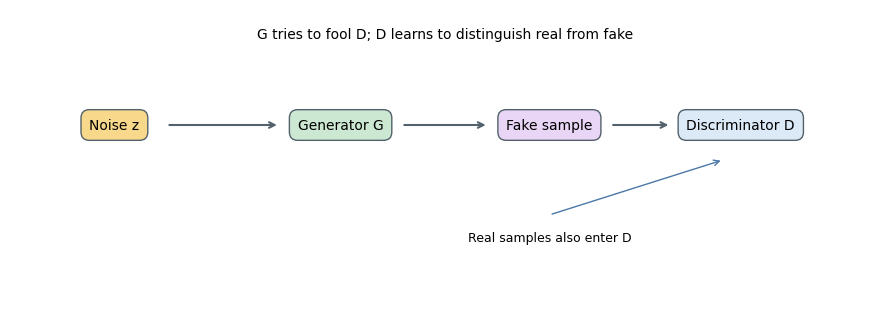

In [16]:
draw_gan_setup()
plt.show()

There is no reconstruction here, and nothing is ever compared with a specific real example. The
only signal the generator ever receives is *the discriminator's opinion*, which is itself changing.

That is why GAN samples are famously sharp — nothing forces the generator to hedge by averaging —
and why GANs are famously painful to train.

### Exercise 8 — a GAN in one dimension

Images would bury the mechanism. Instead, the data is a single number drawn from $N(3, 0.5)$, and
the generator's job is to turn noise into numbers from the same distribution. If it works, the
generated mean approaches 3, the standard deviation approaches 0.5, and the discriminator ends up
answering 0.5 for everything — a coin flip, because it can no longer tell.

The machinery is provided. You write the two loss gradients, which is where the whole idea lives.

In [17]:
class MLP:
    """A small network with its own forward/backward, as in Lab 5."""

    def __init__(s, sizes, seed=0, out_sigmoid=False):
        r = np.random.RandomState(seed)
        s.W, s.b, s.out_sigmoid = [], [], out_sigmoid
        for a, b in zip(sizes[:-1], sizes[1:]):
            s.W.append(r.randn(a, b) * np.sqrt(2.0 / a))
            s.b.append(np.zeros(b))

    def forward(s, x):
        s.acts = [x]; h = x
        for i, (W, b) in enumerate(zip(s.W, s.b)):
            z = h @ W + b
            last = (i == len(s.W) - 1)
            h = sigmoid(z) if (last and s.out_sigmoid) else (z if last else np.maximum(0, z))
            s.acts.append(h)
        return h

    def backward(s, dout):
        gW = [None] * len(s.W); gb = [None] * len(s.b); d = dout
        for i in range(len(s.W) - 1, -1, -1):
            gW[i] = s.acts[i].T @ d; gb[i] = d.sum(0)
            d = d @ s.W[i].T
            if i > 0: d = d * (s.acts[i] > 0)
        return gW, gb, d                      # the last return is d(loss)/d(input)

    def step(s, gW, gb, lr):
        for i in range(len(s.W)):
            s.W[i] -= lr * gW[i]; s.b[i] -= lr * gb[i]


print("MLP ready")

MLP ready


In [18]:
rng = np.random.RandomState(0)
G = MLP([1, 32, 32, 1], seed=1)                    # noise -> a number
D = MLP([1, 32, 32, 1], seed=2, out_sigmoid=True)  # a number -> p(real)

n, lr, D_STEPS = 256, 0.02, 4
steps, g_mean, g_std, p_real, p_fake = [], [], [], [], []

for step in range(3001):
    # ---- train the discriminator: say 1 for real, 0 for fake
    for _ in range(D_STEPS):
        real = rng.normal(3, 0.5, (n, 1))
        fake = G.forward(rng.randn(n, 1))

        d_real = D.forward(real)
        # Completed 1: the discriminator wants d_real to be 1.
        #         With a sigmoid output and cross-entropy, the gradient
        #         at the output is (prediction - target) / n.
        gW1, gb1, _ = D.backward((d_real - 1.0) / n)

        d_fake = D.forward(fake)
        # Completed 2: the same, but the target for a fake is 0
        gW2, gb2, _ = D.backward(d_fake / n)

        D.step([a + b for a, b in zip(gW1, gW2)],
               [a + b for a, b in zip(gb1, gb2)], lr)

    # ---- train the generator: make the discriminator say "real" about fakes
    fake = G.forward(rng.randn(n, 1))
    d_fake = D.forward(fake)
    # Completed 3: the generator wants d_fake to be 1, using the same gradient form as the real target.
    #         We keep the THIRD return value: the gradient w.r.t. D's input,
    #         which is G's output.
    _, _, d_input = D.backward((d_fake - 1.0) / n)

    gW, gb, _ = G.backward(d_input)
    G.step(gW, gb, lr)

    if step % 600 == 0:
        s_ = G.forward(rng.randn(2000, 1))
        steps.append(step); g_mean.append(float(s_.mean())); g_std.append(float(s_.std()))
        p_real.append(float(d_real.mean())); p_fake.append(float(d_fake.mean()))

print(f"{'step':>6}{'fake mean':>11}{'fake std':>10}{'D(real)':>9}{'D(fake)':>9}")
for a, b, c, dd, e in zip(steps, g_mean, g_std, p_real, p_fake):
    print(f"{a:6d}{b:11.2f}{c:10.2f}{dd:9.2f}{e:9.2f}")
print("\ntarget: mean 3.00, std 0.50")

assert abs(g_mean[-1] - 3.0) < 0.3, "the generator should find the mean"
assert abs(g_std[-1] - 0.5) < 0.3, "and the spread"

  step  fake mean  fake std  D(real)  D(fake)
     0       1.18      1.70     0.87     0.47
   600       2.99      0.32     0.50     0.50
  1200       3.02      0.42     0.49     0.50
  1800       3.05      0.50     0.51     0.50
  2400       2.99      0.48     0.50     0.50
  3000       2.98      0.52     0.51     0.50

target: mean 3.00, std 0.50


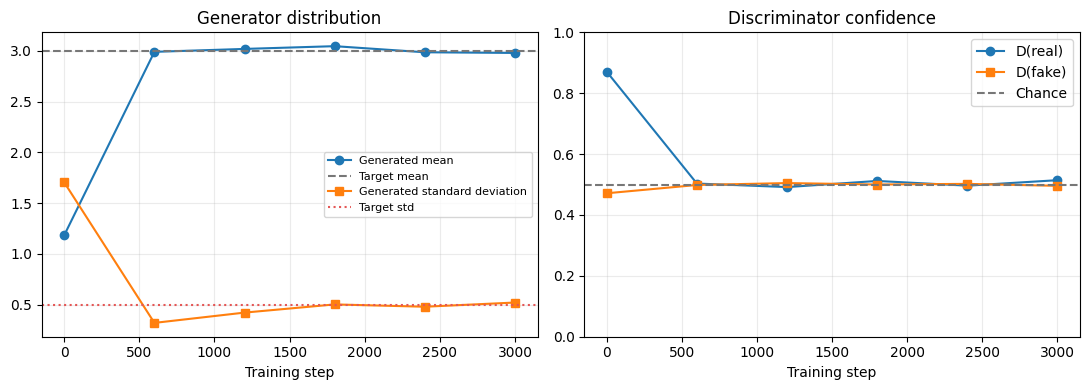

In [19]:
draw_gan_progress(steps, g_mean, g_std, p_real, p_fake,
                  target_mean=3.0, target_std=0.5)
plt.show()

Two things to take from that run.

**It worked**, and the sign that it worked is the right-hand panel: both curves settle at 0.5. The
discriminator is reduced to guessing, which is precisely the equilibrium the paper describes.

**It needed `D_STEPS = 4`.** One discriminator update per generator update was not enough — the
generator found the mean but never the spread, because a weak discriminator could not punish being
too wide. Try changing it to 1 and see. That knob is not in the mathematics anywhere; it is the
kind of thing that makes GANs hard, and it is why the VAE, for all its blurriness, is often the one
people reach for first.

---
# Assessment

## Q1 — The beta table

Fill in from your Stage 4 run.

| beta | reconstruction | KL | code std | judge confidence |
|---|---|---|---|---|
| 0.0 | 17.24 | 86.33 | 2.46 | 0.495 |
| 1.0 | 20.90 | 3.49 | 0.67 | 0.676 |
| 4.0 | 27.21 | 0.00 | 0.01 | 0.300 |

Then answer, in one sentence each:

1. Which row rebuilds best, and which generates best? Why are they not the same row?
2. What single number in the table tells you the beta = 4 model has suffered posterior collapse?

## Q2 — Find the breaking point

Somewhere between `beta = 1` and `beta = 4` the model stops being useful. Narrow it down.

**Answers**

1. beta = 0 should rebuild best because it has no KL pressure pulling codes toward a shared distribution. beta = 1 should generate better because its latent codes are regularized to resemble the normal distribution used for sampling.
2. The code standard deviation near zero is the clearest single sign of posterior collapse: the encoder's means barely vary across input images.


In [20]:
print(f"{'beta':>6}{'recon':>9}{'KL':>8}{'code std':>11}{'judge confidence':>19}")
for beta in [1.0, 1.5, 2.0, 3.0]:
    # Completed: train at this beta for 400 epochs, evaluate on X_test,
    #       and score its generations
    m = train_vae(L=8, beta=beta, epochs=400)
    r, k, mu = evaluate(m, X_test, beta=beta)
    conf = generation_score(m)
    print(f"{beta:6.1f}{r:9.2f}{k:8.2f}{mu.std():11.2f}{conf:19.3f}")

  beta    recon      KL   code std   judge confidence
   1.0    20.90    3.49       0.67              0.676
   1.5    22.58    2.10       0.56              0.621
   2.0    24.34    1.16       0.44              0.543
   3.0    27.12    0.03       0.09              0.288


| beta | reconstruction | KL | code std | judge confidence |
|---|---|---|---|---|
| 1.0 | 20.90 | 3.49 | 0.67 | 0.676 |
| 1.5 | 22.58 | 2.10 | 0.56 | 0.621 |
| 2.0 | 24.34 | 1.16 | 0.44 | 0.543 |
| 3.0 | 27.12 | 0.03 | 0.09 | 0.288 |

State where you would set beta for this dataset, and defend it using two columns of your table.

**Answer:** I would choose beta = 1.0 for this run: it has the highest judge confidence (0.676) among the tested settings while its code standard deviation (0.67) is still clearly above collapse. The results place the collapse transition between beta = 2.0 and 3.0: at 3.0, code std falls to 0.09 and judge confidence to 0.288.


---
## Submission

1. Create a new repository on GitHub for this course and name it `arti402`.
2. Rename this file to `arti402_Lab11_<YourID>.ipynb` and upload the completed notebook, with all
   outputs visible, to your repository.